In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pip install ucimlrepo


In [4]:

from ucimlrepo import fetch_ucirepo

# fetch dataset
covertype = fetch_ucirepo(id=31)

# data (as pandas dataframes)
X = covertype.data.features
y = covertype.data.targets

# metadata
print(covertype.metadata)

# variable information
print(covertype.variables)


{'uci_id': 31, 'name': 'Covertype', 'repository_url': 'https://archive.ics.uci.edu/dataset/31/covertype', 'data_url': 'https://archive.ics.uci.edu/static/public/31/data.csv', 'abstract': 'Classification of pixels into 7 forest cover types based on attributes such as elevation, aspect, slope, hillshade, soil-type, and more.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 581012, 'num_features': 54, 'feature_types': ['Categorical', 'Integer'], 'demographics': [], 'target_col': ['Cover_Type'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sat Mar 16 2024', 'dataset_doi': '10.24432/C50K5N', 'creators': ['Jock Blackard'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting forest cover type from cartographic variables only (no remotely sensed data).  The actual forest cover type for a given observation (30 x 30 meter cell) was determined from

In [7]:
# Subtract 1 to shift classes from [1-7] to [0-6] for zero-indexing
y_zero_indexed = y['Cover_Type'] - 1

# Or modify y in-place
y['Cover_Type'] = y['Cover_Type'] - 1

# Confirm the transformation
print("Original unique values (minus 1):", y['Cover_Type'].unique())
display(y.head())

Original unique values (minus 1): [ 2 -1 -2  4  0  3  1]


/tmp/ipykernel_4087/4284040224.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y['Cover_Type'] = y['Cover_Type'] - 1


,Cover_Type
0,2
1,2
2,-1
3,-1
4,2


Corrected Class Counts (0 to 6):
 Cover_Type
0    211840
1    283301
2     35754
3      2747
4      9493
5     17367
6     20510
Name: count, dtype: int64


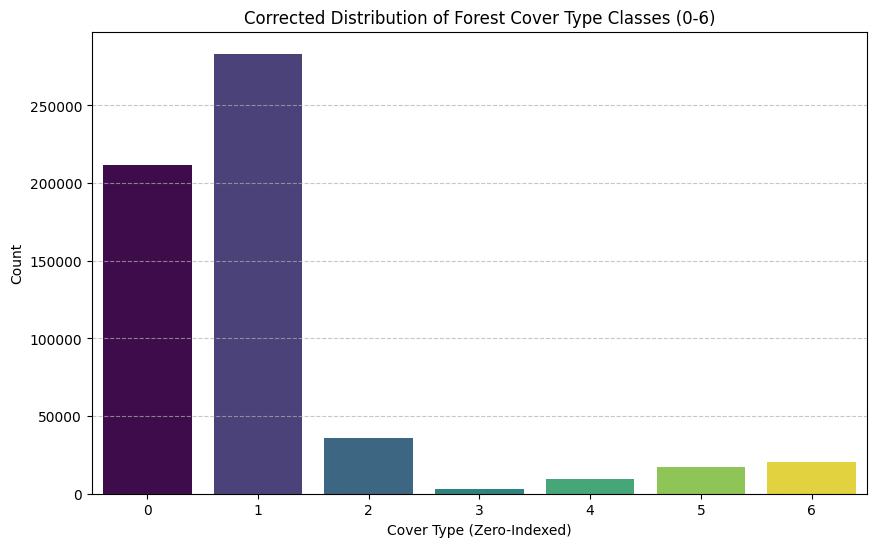

In [10]:
# Re-import and re-fetch a completely clean, unmodified dataset to reset values
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fetch the dataset fresh to guarantee target labels are back to [1-7]
covertype_clean = fetch_ucirepo(id=31)

# 2. Extract and subtract 1 exactly once to get [0-6]
X = covertype_clean.data.features
y = covertype_clean.data.targets.copy()
y['Cover_Type'] = y['Cover_Type'] - 1

# Calculate the corrected zero-indexed distribution
class_counts = y['Cover_Type'].value_counts().sort_index()
print("Corrected Class Counts (0 to 6):\n", class_counts)

# Visualize the corrected class distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='Cover_Type', data=y, palette='viridis', hue='Cover_Type', legend=False)
plt.title('Corrected Distribution of Forest Cover Type Classes (0-6)')
plt.xlabel('Cover Type (Zero-Indexed)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np


y_encoded = pd.get_dummies(y['Cover_Type']).astype(int).to_numpy()
print(f"One-hot encoded targets shape: {y_encoded.shape}")


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y['Cover_Type']
)

y_temp_labels = np.argmax(y_temp, axis=1)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_labels
)


print(f"\nData Splits:")
print(f"Training set:   X: {X_train.shape}, y: {y_train.shape} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation set: X: {X_val.shape}, y: {y_val.shape} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Testing set:    X: {X_test.shape}, y: {y_test.shape} ({len(X_test)/len(X)*100:.1f}%)")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures have been successfully standardized!")

One-hot encoded targets shape: (581012, 7)

Data Splits:
Training set:   X: (464809, 54), y: (464809, 7) (80.0%)
Validation set: X: (58101, 54), y: (58101, 7) (10.0%)
Testing set:    X: (58102, 54), y: (58102, 7) (10.0%)

Features have been successfully standardized!


In [12]:
import numpy as np


N = len(y)
K = 7
class_counts_dict = class_counts.to_dict()

class_weights = {}
for c in range(K):
    nc = class_counts_dict[c]
    class_weights[c] = N / (K * nc)

print("Calculated Class Weights:")
for c, w in class_weights.items():
    print(f"  Class {c}: {w:.4f}")


layer_dims = [54, 64, 32, 16, 7]

np.random.seed(42)
parameters = {}
L = len(layer_dims)
for l in range(1, L):

    std_dev = np.sqrt(2.0 / layer_dims[l-1])
    parameters[f'W{l}'] = np.random.normal(0, std_dev, (layer_dims[l], layer_dims[l-1]))
    parameters[f'b{l}'] = np.zeros((layer_dims[l], 1))

    print(f"Layer {l} initialized:")
    print(f"  W{l} shape: {parameters[f'W{l}'].shape} (std: {std_dev:.4f})")
    print(f"  b{l} shape: {parameters[f'b{l}'].shape}")


def relu(Z):
    return np.maximum(0, Z)

def softmax(Z):

    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)

def forward_propagation(X_batch, parameters):
    """
    X_batch: input matrix of shape (input_features, batch_size)
    """
    caches = {}
    A = X_batch
    L = len(layer_dims)


    for l in range(1, L - 1):
        W = parameters[f'W{l}']
        b = parameters[f'b{l}']
        Z = np.dot(W, A) + b
        A = relu(Z)
        caches[f'Z{l}'] = Z
        caches[f'A{l}'] = A


    W_out = parameters[f'W{L-1}']
    b_out = parameters[f'b{L-1}']
    Z_out = np.dot(W_out, A) + b_out
    A_out = softmax(Z_out)
    caches[f'Z{L-1}'] = Z_out
    caches[f'A{L-1}'] = A_out

    return A_out, caches

Calculated Class Weights:
  Class 0: 0.3918
  Class 1: 0.2930
  Class 2: 2.3215
  Class 3: 30.2154
  Class 4: 8.7435
  Class 5: 4.7793
  Class 6: 4.0469
Layer 1 initialized:
  W1 shape: (64, 54) (std: 0.1925)
  b1 shape: (64, 1)
Layer 2 initialized:
  W2 shape: (32, 64) (std: 0.1768)
  b2 shape: (32, 1)
Layer 3 initialized:
  W3 shape: (16, 32) (std: 0.2500)
  b3 shape: (16, 1)
Layer 4 initialized:
  W4 shape: (7, 16) (std: 0.3536)
  b4 shape: (7, 1)


In [15]:
def compute_weighted_loss(A_out, Y, class_weights):
    epsilon = 1e-15
    A_out = np.clip(A_out, epsilon, 1 - epsilon)

    weights_vector = np.array([class_weights[c] for c in range(len(class_weights))]).reshape(-1, 1)

    loss_per_sample = -np.sum(Y * np.log(A_out) * weights_vector, axis=0)

    return np.mean(loss_per_sample)

In [17]:
def backward_propagation(X_batch, Y, caches, parameters, class_weights):
    m = X_batch.shape[1]
    grads = {}
    L = len(layer_dims)

    A_out = caches[f'A{L-1}']

    weights_vector = np.array([class_weights[c] for c in range(len(class_weights))]).reshape(-1, 1)

    dZ_out = (A_out - Y) * weights_vector

    A_prev = caches[f'A{L-2}'] if L-2 > 0 else X_batch
    grads[f'dW{L-1}'] = np.dot(dZ_out, A_prev.T) / m
    grads[f'db{L-1}'] = np.sum(dZ_out, axis=1, keepdims=True) / m

    dZ = dZ_out
    for l in reversed(range(1, L-1)):
        W_next = parameters[f'W{l+1}']
        Z_current = caches[f'Z{l}']
        A_prev = caches[f'A{l-1}'] if l-1 > 0 else X_batch

        dA = np.dot(W_next.T, dZ)
        dZ = dA * (Z_current > 0)

        grads[f'dW{l}'] = np.dot(dZ, A_prev.T) / m
        grads[f'db{l}'] = np.sum(dZ, axis=1, keepdims=True) / m

    return grads

In [18]:
def update_parameters(parameters, grads, learning_rate):
    L = len(layer_dims)
    for l in range(1, L):
        parameters[f'W{l}'] -= learning_rate * grads[f'dW{l}']
        parameters[f'b{l}'] -= learning_rate * grads[f'db{l}']
    return parameters

def train_model(X_train, y_train, X_val, y_val, parameters, class_weights, epochs=100, batch_size=256, learning_rate=0.01, patience=15):
    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    best_parameters = {}
    epochs_no_improve = 0

    num_samples = X_train.shape[1]

    for epoch in range(epochs):
        permutation = np.random.permutation(num_samples)
        X_shuffled = X_train[:, permutation]
        y_shuffled = y_train[:, permutation]

        epoch_loss = 0
        num_batches = int(np.ceil(num_samples / batch_size))

        for i in range(num_batches):
            start_idx = i * batch_size
            end_idx = min(start_idx + batch_size, num_samples)

            X_batch = X_shuffled[:, start_idx:end_idx]
            y_batch = y_shuffled[:, start_idx:end_idx]

            A_out, caches = forward_propagation(X_batch, parameters)
            loss = compute_weighted_loss(A_out, y_batch, class_weights)
            epoch_loss += loss * (end_idx - start_idx)

            grads = backward_propagation(X_batch, y_batch, caches, parameters, class_weights)
            parameters = update_parameters(parameters, grads, learning_rate)

        epoch_loss /= num_samples
        train_losses.append(epoch_loss)

        val_out, _ = forward_propagation(X_val, parameters)
        val_loss = compute_weighted_loss(val_out, y_val, class_weights)
        val_losses.append(val_loss)

        print(f"Epoch {epoch+1:03d}/{epochs:03d} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_parameters = {k: v.copy() for k, v in parameters.items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered. No improvement in validation loss for {patience} epochs.")
                break

    return best_parameters, train_losses, val_losses

In [19]:
X_train_t = X_train_scaled.T
y_train_t = y_train.T
X_val_t = X_val_scaled.T
y_val_t = y_val.T

final_parameters, train_losses, val_losses = train_model(
    X_train_t,
    y_train_t,
    X_val_t,
    y_val_t,
    parameters,
    class_weights,
    epochs=100,
    batch_size=512,
    learning_rate=0.05,
    patience=15
)

Epoch 001/100 | Train Loss: 1.3503 | Val Loss: 1.0407
Epoch 002/100 | Train Loss: 1.0651 | Val Loss: 1.0111
Epoch 003/100 | Train Loss: 0.9931 | Val Loss: 0.9441
Epoch 004/100 | Train Loss: 0.9368 | Val Loss: 0.9445
Epoch 005/100 | Train Loss: 0.8853 | Val Loss: 0.7974
Epoch 006/100 | Train Loss: 0.8455 | Val Loss: 0.7615
Epoch 007/100 | Train Loss: 0.8126 | Val Loss: 0.8509
Epoch 008/100 | Train Loss: 0.7905 | Val Loss: 0.8978
Epoch 009/100 | Train Loss: 0.7695 | Val Loss: 0.6976
Epoch 010/100 | Train Loss: 0.7511 | Val Loss: 0.7821
Epoch 011/100 | Train Loss: 0.7542 | Val Loss: 0.7740
Epoch 012/100 | Train Loss: 0.7374 | Val Loss: 0.7087
Epoch 013/100 | Train Loss: 0.7183 | Val Loss: 0.8238
Epoch 014/100 | Train Loss: 0.7092 | Val Loss: 0.6397
Epoch 015/100 | Train Loss: 0.7029 | Val Loss: 0.6511
Epoch 016/100 | Train Loss: 0.6792 | Val Loss: 0.6332
Epoch 017/100 | Train Loss: 0.6916 | Val Loss: 0.7150
Epoch 018/100 | Train Loss: 0.6750 | Val Loss: 0.7831
Epoch 019/100 | Train Loss: 

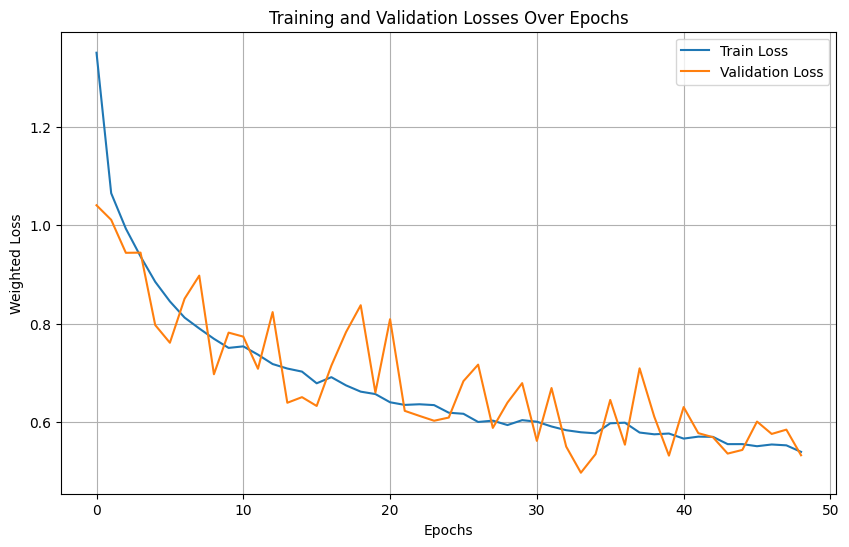

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Losses Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Weighted Loss')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
X_test_t = X_test_scaled.T
test_probabilities, _ = forward_propagation(X_test_t, final_parameters)
test_predictions = np.argmax(test_probabilities, axis=0)

print("Predicted class probabilities shape:", test_probabilities.shape)
print("Predicted class labels shape:", test_predictions.shape)
print("Sample predictions:", test_predictions[:10])

Predicted class probabilities shape: (7, 58102)
Predicted class labels shape: (58102,)
Sample predictions: [0 1 1 0 2 1 1 1 1 4]


Overall Test Accuracy: 0.7783

Per-Class Metrics:
  Class 0 -> Precision: 0.7360 | Recall: 0.7694 | F1-Score: 0.7524 | Support: 21184
  Class 1 -> Precision: 0.8252 | Recall: 0.7724 | F1-Score: 0.7979 | Support: 28331
  Class 2 -> Precision: 0.7881 | Recall: 0.8487 | F1-Score: 0.8173 | Support: 3576
  Class 3 -> Precision: 0.7092 | Recall: 0.8723 | F1-Score: 0.7823 | Support: 274
  Class 4 -> Precision: 0.7069 | Recall: 0.8030 | F1-Score: 0.7519 | Support: 949
  Class 5 -> Precision: 0.7540 | Recall: 0.5999 | F1-Score: 0.6682 | Support: 1737
  Class 6 -> Precision: 0.7015 | Recall: 0.9556 | F1-Score: 0.8091 | Support: 2051

Macro Metrics:
  Macro Precision: 0.7458
  Macro Recall: 0.8030
  Macro F1-Score: 0.7684


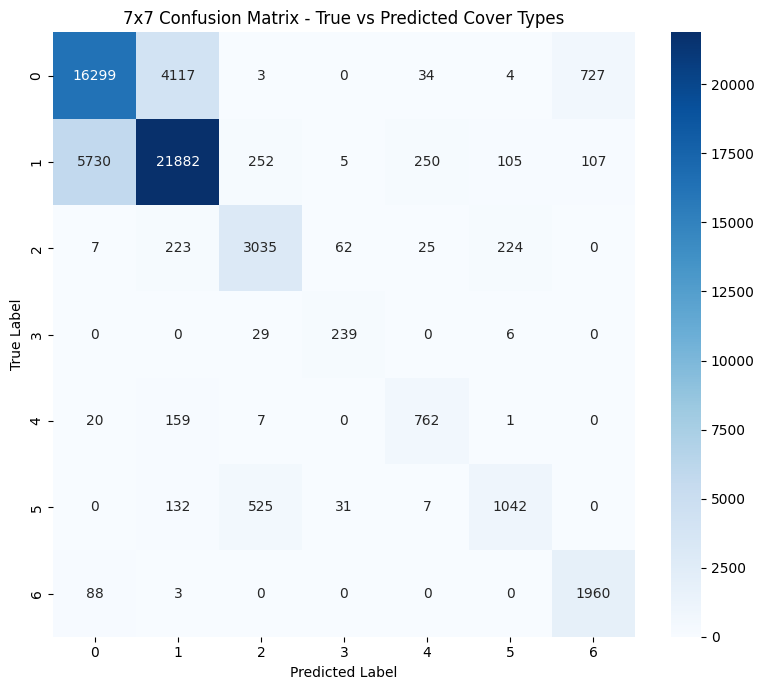

In [22]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y_true = np.argmax(y_test, axis=1)

accuracy = accuracy_score(y_true, test_predictions)
precision, recall, f1, support = precision_recall_fscore_support(y_true, test_predictions, average=None)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(y_true, test_predictions, average='macro')

print(f"Overall Test Accuracy: {accuracy:.4f}\n")
print("Per-Class Metrics:")
for c in range(7):
    print(f"  Class {c} -> Precision: {precision[c]:.4f} | Recall: {recall[c]:.4f} | F1-Score: {f1[c]:.4f} | Support: {support[c]}")

print(f"\nMacro Metrics:\n  Macro Precision: {macro_precision:.4f}\n  Macro Recall: {macro_recall:.4f}\n  Macro F1-Score: {macro_f1:.4f}")

cm = confusion_matrix(y_true, test_predictions)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(range(7)), yticklabels=list(range(7)))
plt.title('7x7 Confusion Matrix - True vs Predicted Cover Types')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

### Training and Validation Loss Curves

Let's visualize how the loss progressed across epochs for both the training and validation splits.

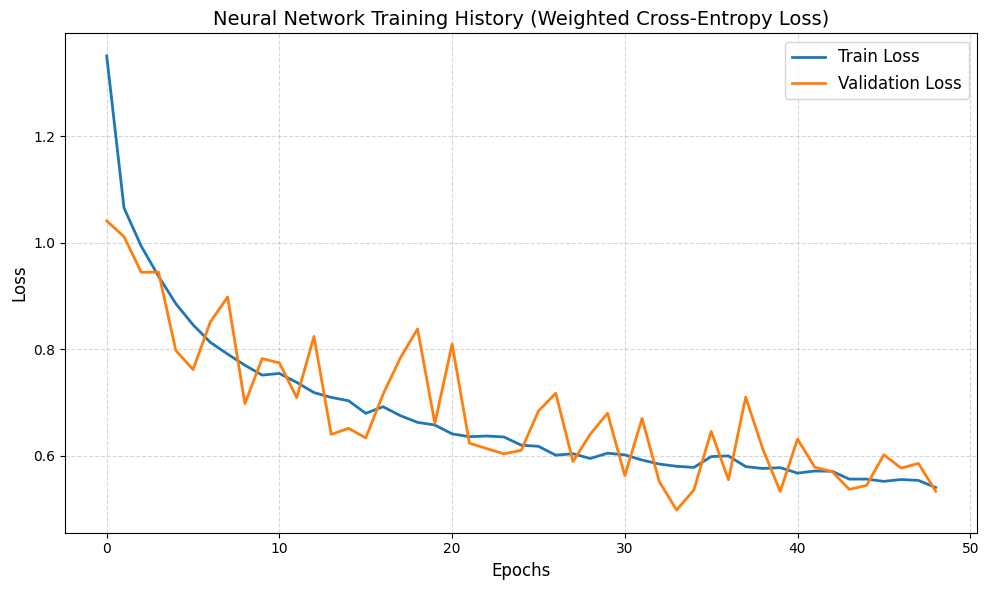

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='#ff7f0e', linewidth=2)
plt.title('Neural Network Training History (Weighted Cross-Entropy Loss)', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Annotated Confusion Matrix Heatmap

Let's plot a dedicated, highly readable 7x7 confusion matrix heatmap with annotations using Seaborn to visualize how our model performs across the various forest cover type classes.

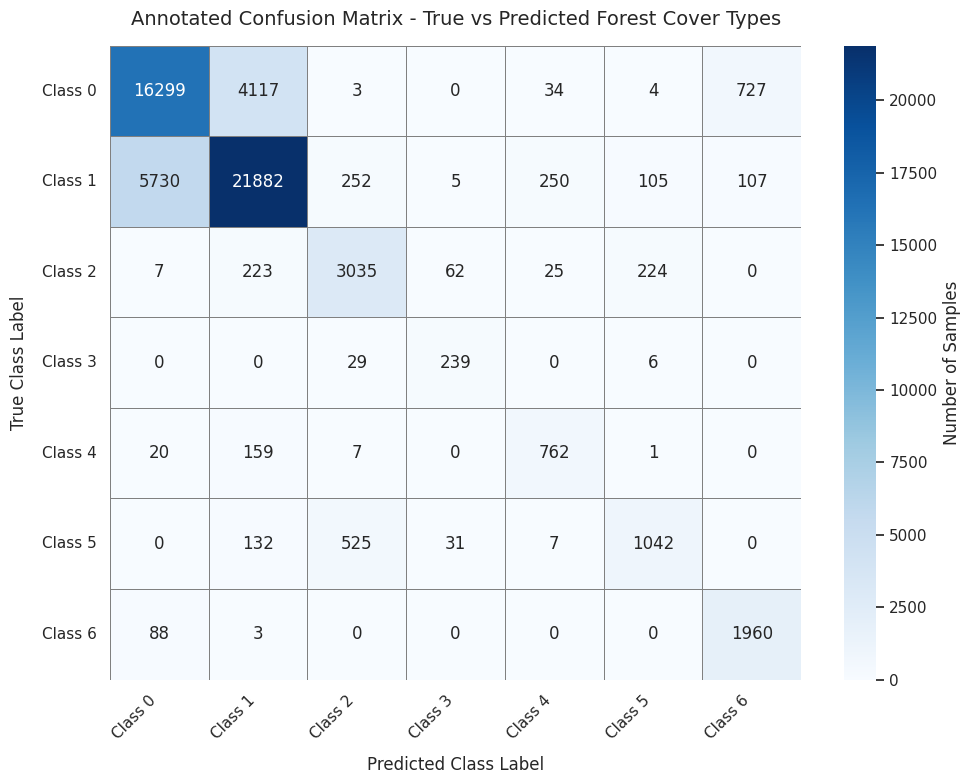

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure figure size and aesthetics
plt.figure(figsize=(10, 8))
sns.set_theme(style="white")

# Plot the confusion matrix as a heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    linecolor='gray',
    xticklabels=[f'Class {i}' for i in range(7)],
    yticklabels=[f'Class {i}' for i in range(7)],
    cbar_kws={'label': 'Number of Samples'}
)

plt.title('Annotated Confusion Matrix - True vs Predicted Forest Cover Types', fontsize=14, pad=15)
plt.xlabel('Predicted Class Label', fontsize=12, labelpad=10)
plt.ylabel('True Class Label', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Detailed Per-Class Evaluation & Distribution Comparison

To thoroughly analyze our neural network's performance, we will:
1. Plot the **per-class F1-scores**.
2. Compare **Precision vs. Recall** for each cover type class.
3. Compare the **True vs. Predicted** label distributions on the test set.

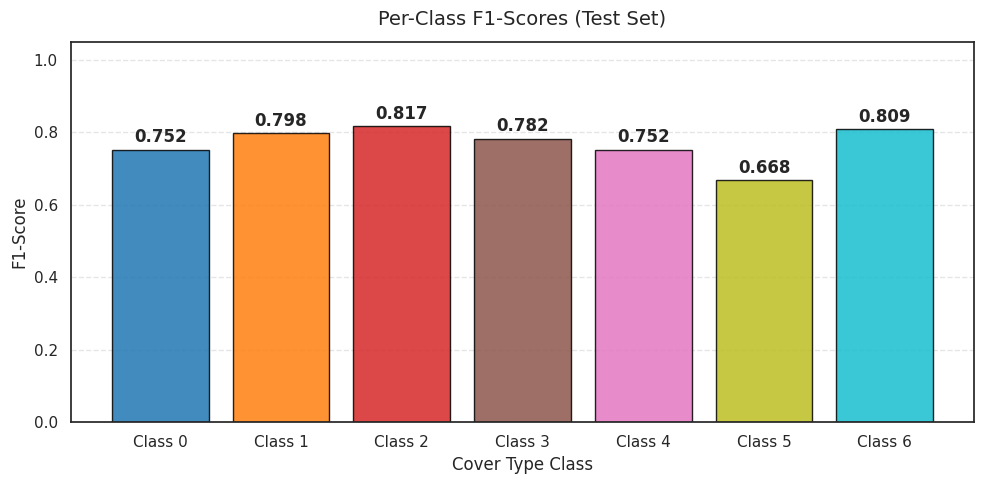

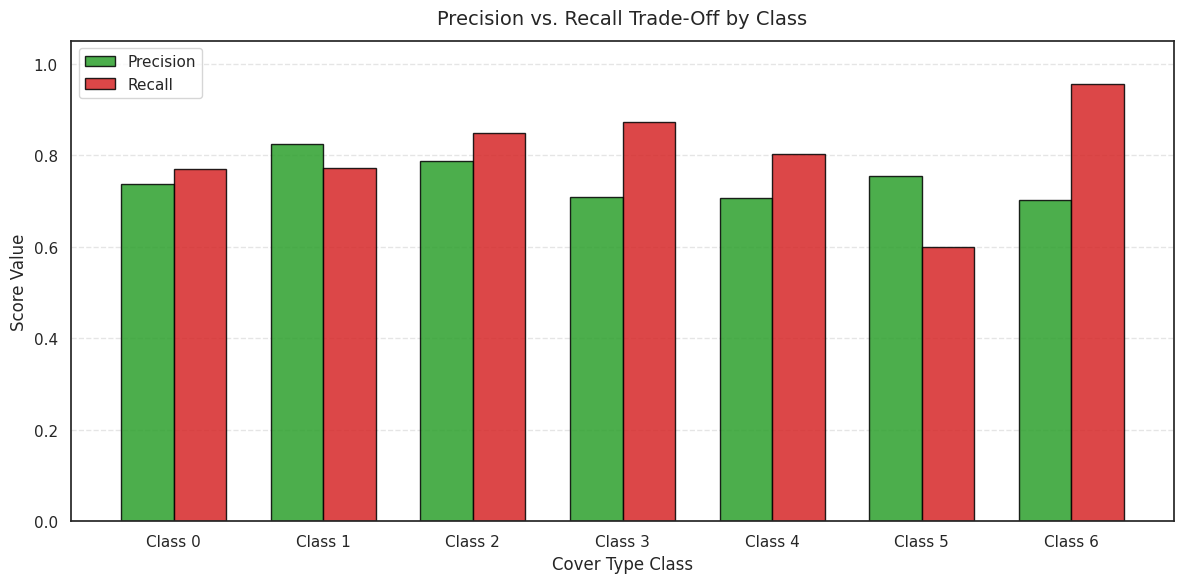

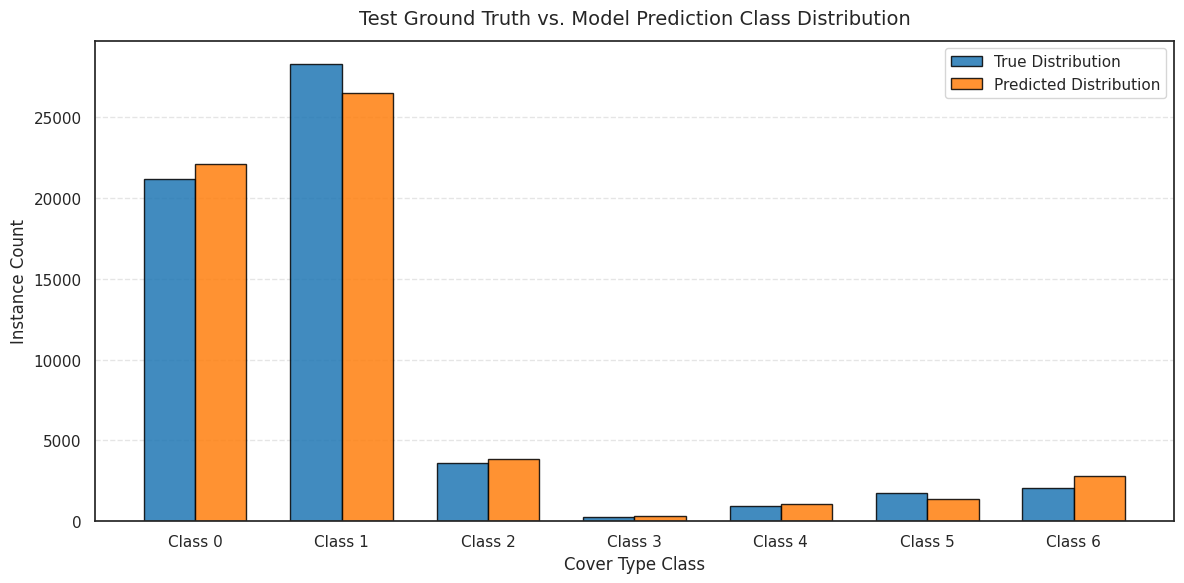

In [25]:
import matplotlib.pyplot as plt
import numpy as np

classes = [f'Class {i}' for i in range(7)]

# --- Plot 1: Per-Class F1-Scores ---
plt.figure(figsize=(10, 5))
colors = plt.cm.tab10(np.linspace(0, 1, 7))
plt.bar(classes, f1, color=colors, edgecolor='black', alpha=0.85)
plt.title('Per-Class F1-Scores (Test Set)', fontsize=14, pad=12)
plt.xlabel('Cover Type Class', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.ylim(0, 1.05)
for i, val in enumerate(f1):
    plt.text(i, val + 0.02, f"{val:.3f}", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# --- Plot 2: Precision vs. Recall Comparison ---
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, precision, width, label='Precision', color='#2ca02c', alpha=0.85, edgecolor='black')
plt.bar(x + width/2, recall, width, label='Recall', color='#d62728', alpha=0.85, edgecolor='black')
plt.title('Precision vs. Recall Trade-Off by Class', fontsize=14, pad=12)
plt.xlabel('Cover Type Class', fontsize=12)
plt.ylabel('Score Value', fontsize=12)
plt.xticks(x, classes)
plt.ylim(0, 1.05)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# --- Plot 3: True vs. Predicted Label Distribution ---
unique_true, counts_true = np.unique(y_true, return_counts=True)
unique_pred, counts_pred = np.unique(test_predictions, return_counts=True)

# Handle potential missing classes in prediction array mapping
pred_dict = dict(zip(unique_pred, counts_pred))
true_dict = dict(zip(unique_true, counts_true))
counts_pred_aligned = [pred_dict.get(i, 0) for i in range(7)]
counts_true_aligned = [true_dict.get(i, 0) for i in range(7)]

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, counts_true_aligned, width, label='True Distribution', color='#1f77b4', alpha=0.85, edgecolor='black')
plt.bar(x + width/2, counts_pred_aligned, width, label='Predicted Distribution', color='#ff7f0e', alpha=0.85, edgecolor='black')
plt.title('Test Ground Truth vs. Model Prediction Class Distribution', fontsize=14, pad=12)
plt.xlabel('Cover Type Class', fontsize=12)
plt.ylabel('Instance Count', fontsize=12)
plt.xticks(x, classes)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Overall Model Accuracy

Let's print the final calculated overall accuracy of our trained multi-class neural network on the unseen test set.

In [26]:
print(f"The overall model classification accuracy on the test set is: {accuracy * 100:.2f}%")

The overall model classification accuracy on the test set is: 77.83%
